# Noise-Robust Spoken Digit Recognition with STFT, MFCC and Spectral Subtraction

**Research question:** *Does spectral-subtraction speech enhancement make an MFCC + CNN speech recogniser more robust to noise, and how does it compare with training on noisy data?*

This notebook rebuilds the original speech-processing project as one controlled experiment:

| Step | What happens | Report section it feeds |
|---|---|---|
| 0–1 | Setup, configuration, reproducibility | Methodology → Tools |
| 2–3 | Load the **Free Spoken Digit Dataset (FSDD)**, explore it, split it properly | Methodology → Data |
| 4 | Pre-process (DC removal, normalisation, fixed length, silence padding) | Methodology → Preprocessing |
| 5 | Signal analysis: waveform, STFT spectrogram, mel spectrogram, MFCC | Fundamentals / Results 1 |
| 6 | Add **controlled noise** (white + babble) at 20/10/5/0 dB SNR | Methodology → Noise |
| 7 | **Spectral subtraction** (vectorised, power-domain, Berouti over-subtraction + spectral floor) | Methodology → Enhancement |
| 8 | MFCC + Δ + ΔΔ feature extraction (batched) | Methodology → Features |
| 9 | Train **Model A** (CNN, clean data) | Methodology → Classifier |
| 10 | Tune enhancement parameters (α, β) on the **validation** set | Methodology → Tuning |
| 11 | Objective enhancement metrics on the test set: SNR, SegSNR, **PESQ**, **STOI** | Results 2 |
| 12 | **Robustness experiment**: accuracy vs SNR for noisy vs enhanced inputs | Results 3 (headline) |
| 13 | Train **Model B** (multi-condition training) and compare | Results 4 |
| 14 | Automatic summary of findings + saved outputs | Discussion / Conclusion |

### How to run on Kaggle
1. **Add data → search "Free Spoken Digit Dataset (FSDD)"** (`joserzapata/free-spoken-digit-dataset-fsdd`) and attach it. The notebook finds the `.wav` files anywhere under `/kaggle/input`, so the exact folder layout doesn't matter.
2. **Settings → Internet: On** (needed only to `pip install pesq pystoi`; if Internet is off, PESQ/STOI are skipped and everything else still runs. Without the dataset attached, Internet On also lets the notebook clone FSDD from GitHub automatically).
3. **Accelerator:** GPU T4 recommended but optional (mixed precision is switched on automatically). The full run took about 30 minutes on a 2-core CPU in testing, mostly CNN training; a GPU cuts this considerably.
4. **Run All.** Every figure, table, audio example and trained model is saved to `/kaggle/working/outputs/`.

## Step 0 — Install the two extra packages

`librosa`, `tensorflow`, `scikit-learn`, `seaborn` are pre-installed on Kaggle. We only need:
- **`pesq`** — Perceptual Evaluation of Speech Quality (ITU-T P.862), a standard score of how good speech *sounds* (≈1 = bad, ≈4.5 = excellent).
- **`pystoi`** — Short-Time Objective Intelligibility, a 0–1 score of how *understandable* speech is.

The install is wrapped so the notebook keeps running if Internet is off.

In [1]:
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pesq", "pystoi"],
                   capture_output=True, text=True)
print("pip install pesq pystoi:", "OK" if r.returncode == 0 else "FAILED (metrics will be skipped)\n" + r.stderr[-500:])

pip install pesq pystoi: OK


## Step 1 — Imports, configuration and reproducibility

**What we're doing:** putting *every* tunable number in one cell so the report can quote exact parameters, and fixing random seeds so results are reproducible.

**Key signal-processing choices (FSDD is sampled at 8 kHz):**
- **Frame / FFT size 256 samples = 32 ms** — speech is roughly stationary over 20–40 ms, so this is the classic STFT window.
- **Feature hop 80 samples = 10 ms** — the standard frame rate for speech features.
- **Enhancement hop 64 samples (75 % overlap)** — more overlap gives cleaner reconstruction after spectral subtraction.
- **40 mel filters → MFCC 1–20** (C0, the overall loudness term, is dropped because it is the coefficient most sensitive to noise and volume).

**Efficiency choices:** all signals are padded to the same length so STFT, spectral subtraction and MFCC run on whole *batches* as NumPy arrays instead of Python loops; mixed precision is switched on only when a modern GPU is present.

In [2]:
import os, re, glob, time, warnings, zlib
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display
import soundfile as sf
import scipy.fft
from joblib import Parallel, delayed
from IPython.display import Audio, display
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# ----------------------------- configuration -----------------------------
SEED        = 42
SR          = 8000                 # FSDD sampling rate (Hz)
SPEECH_LEN  = SR                   # speech region fixed to 1.0 s (99 % of clips are shorter)
PAD         = int(0.25 * SR)       # 0.25 s of silence before and after -> known noise-only region
TOTAL_LEN   = SPEECH_LEN + 2 * PAD # 1.5 s per example
DITHER_SNR  = 50                   # tiny noise floor so the padding isn't digital silence (dB)

N_FFT       = 256                  # 32 ms analysis window
HOP_FEAT    = 80                   # 10 ms hop for features
HOP_ENH     = 64                   # 8 ms hop (75 % overlap) for enhancement
N_MELS      = 40
N_MFCC      = 20                   # keep C1..C20, drop C0

NOISE_TYPES = ["white", "babble"]
SNRS        = [20, 10, 5, 0]       # test SNRs (dB)
TUNE_SNRS   = [10, 5, 0]           # SNRs used to tune alpha/beta on the validation set
ALPHA_GRID  = [1, 2, 4, 6, 9, 12]  # over-subtraction factors
BETA_GRID   = [0.02, 0.1, 0.3]     # spectral floor
NOISE_FRAC  = 0.15                 # lowest-energy 15 % of frames used to estimate noise

SPLIT_MODE   = "standard"          # "standard" = official FSDD split | "speaker" = unseen-speaker test
TEST_SPEAKER = "theo"              # used only when SPLIT_MODE == "speaker"

BATCH       = 64
EPOCHS      = 80                   # upper bound; early stopping decides
LR          = 1e-3
SPECAUGMENT = True                 # random time/frequency masking during training

N_JOBS      = os.cpu_count() or 2
OUT_DIR     = "/kaggle/working/outputs" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# ----------------------------- reproducibility ---------------------------
tf.keras.utils.set_random_seed(SEED)       # seeds Python, NumPy and TensorFlow
rng_master = np.random.default_rng(SEED)

# ----------------------------- hardware ----------------------------------
gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
MIXED = False
if gpus:
    cc = tf.config.experimental.get_device_details(gpus[0]).get("compute_capability", (0, 0))
    if cc and cc[0] >= 7:                    # tensor cores (T4, V100, A100...)
        tf.keras.mixed_precision.set_global_policy("mixed_float16")
        MIXED = True

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150})

def save(fig, name):
    fig.savefig(f"{OUT_DIR}/{name}.png", bbox_inches="tight")

def batched(fn, X, bs=256, **kw):
    # apply a vectorised function to a big array in memory-friendly chunks
    return np.concatenate([fn(X[i:i + bs], **kw) for i in range(0, len(X), bs)], axis=0)

print(f"TensorFlow {tf.__version__} | librosa {librosa.__version__} | CPUs {N_JOBS} | "
      f"GPU {[g.name for g in gpus] or 'none'} | mixed precision {MIXED}")
print("Outputs ->", OUT_DIR)

I0000 00:00:1793048487.435456     200 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | librosa 1.0.0 | CPUs 2 | GPU none | mixed precision False
Outputs -> outputs


I0000 00:00:1793048488.750669     200 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Step 2 — Find and load the dataset

**What we're doing:** FSDD contains 3,000 recordings: 6 speakers × 10 digits × 50 repetitions, 8 kHz mono WAV. Files are named `{digit}_{speaker}_{index}.wav`, so the label and speaker come straight from the filename.

**How it is found:** we search `/kaggle/input` recursively for files matching that naming pattern (so it works whatever folder structure the Kaggle upload uses) and remove duplicates. If nothing is attached, we clone the official GitHub repository instead.

**Efficiency:** files are read in parallel with `joblib`.

In [3]:
PATTERN = re.compile(r"^(\d)_([a-z]+)_(\d+)\.wav$")

def find_fsdd():
    candidates = glob.glob("/kaggle/input/**/*.wav", recursive=True)
    candidates += glob.glob("free-spoken-digit-dataset/recordings/*.wav")
    found = {}
    for p in sorted(candidates):
        name = os.path.basename(p)
        if PATTERN.match(name) and name not in found:     # de-duplicate by file name
            found[name] = p
    if len(found) < 1500:
        print("FSDD not found locally -> cloning from GitHub (needs Internet on)...")
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/Jakobovski/free-spoken-digit-dataset.git"], check=True)
        return find_fsdd()
    return list(found.values())

paths = find_fsdd()

def load(path):
    y, sr = sf.read(path, dtype="float32")
    if y.ndim > 1:
        y = y.mean(axis=1)
    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    return y

t0 = time.time()
waves = Parallel(n_jobs=N_JOBS, prefer="threads")(delayed(load)(p) for p in paths)

meta = pd.DataFrame([PATTERN.match(os.path.basename(p)).groups() for p in paths],
                    columns=["digit", "speaker", "index"]).astype({"digit": int, "index": int})
meta["path"] = paths
meta["n_samples"] = [len(w) for w in waves]
meta["duration_s"] = meta["n_samples"] / SR
print(f"Loaded {len(meta)} recordings from {meta.speaker.nunique()} speakers in {time.time()-t0:.1f} s")
meta.head()

Loaded 3000 recordings from 6 speakers in 2.2 s


,digit,speaker,index,path,n_samples,duration_s
0,0,george,0,free-spoken-digit-dataset/recordings/0_george_...,2384,0.298000
1,0,george,1,free-spoken-digit-dataset/recordings/0_george_...,4727,0.590875
2,0,george,10,free-spoken-digit-dataset/recordings/0_george_...,5958,0.744750
3,0,george,11,free-spoken-digit-dataset/recordings/0_george_...,3661,0.457625
4,0,george,12,free-spoken-digit-dataset/recordings/0_george_...,4050,0.506250


## Step 3 — Explore the data and split it correctly

**Split (the most important fix vs. the original code):**
- `SPLIT_MODE = "standard"` uses the **official FSDD split**: recordings with index 0–4 are the test set. We additionally use index 5–9 as a **validation** set, so the test set is never touched during training or tuning. Test clips are different recordings from training clips, but the speakers are the same (*speaker-dependent* recognition).
- `SPLIT_MODE = "speaker"` holds out one speaker entirely, a harder *speaker-independent* test. Switch it in Step 1 to try it.

The original code split 1-second chunks of the same recording randomly, so near-identical audio ended up in both train and test. Here a recording is in exactly one set.

split     test  train  val   All
speaker                         
george      50    400   50   500
jackson     50    400   50   500
lucas       50    400   50   500
nicolas     50    400   50   500
theo        50    400   50   500
yweweler    50    400   50   500
All        300   2400  300  3000


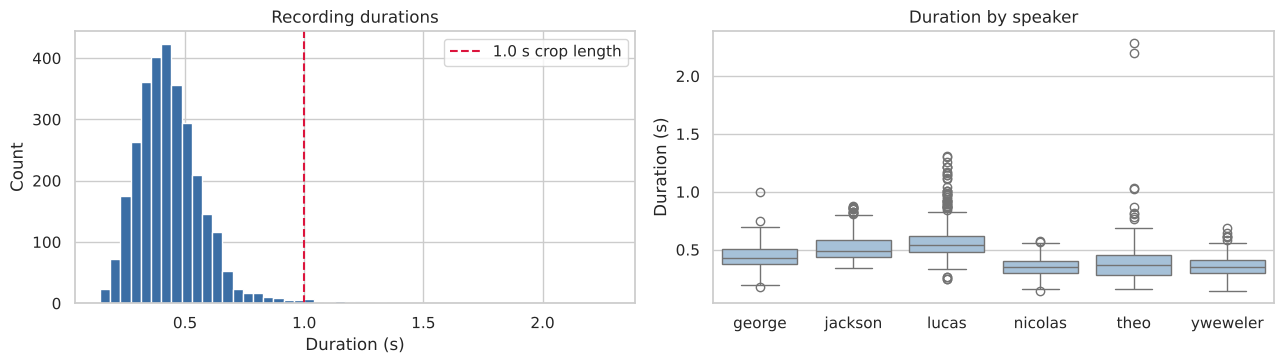

Clips longer than 1 s (center-cropped): 0.67 %


In [4]:
if SPLIT_MODE == "standard":
    meta["split"] = np.select([meta["index"] <= 4, meta["index"] <= 9], ["test", "val"], "train")
else:
    meta["split"] = np.where(meta.speaker == TEST_SPEAKER, "test",
                             np.where(meta["index"] <= 4, "val", "train"))

print(pd.crosstab(meta.speaker, meta.split, margins=True))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(meta.duration_s, bins=50, color="#3b6ea5")
ax[0].axvline(SPEECH_LEN / SR, color="crimson", ls="--", label="1.0 s crop length")
ax[0].set(title="Recording durations", xlabel="Duration (s)", ylabel="Count"); ax[0].legend()
sns.boxplot(data=meta, x="speaker", y="duration_s", ax=ax[1], color="#9ec1e0")
ax[1].set(title="Duration by speaker", xlabel="", ylabel="Duration (s)")
plt.tight_layout(); save(fig, "01_dataset_durations"); plt.show()
print(f"Clips longer than 1 s (center-cropped): {(meta.n_samples > SPEECH_LEN).mean()*100:.2f} %")

## Step 4 — Pre-processing

For every recording we:
1. **Remove DC offset** (subtract the mean) so the signal is centred on zero.
2. **Peak-normalise** to 0.9 so every clip uses the same amplitude range (this was the original code's normalisation step).
3. **Fix the length**: centre-crop clips longer than 1 s, centre clips shorter than 1 s inside a 1 s window.
4. **Pad 0.25 s of silence on both sides** (1.5 s total). This guarantees a noise-only region exists, which spectral subtraction needs to estimate the noise. The original code *assumed* the first 0.5 s was silence.
5. Add a **very low noise floor (50 dB below the speech)** so padded regions are not perfect digital zeros, which never occur in real recordings.

We also store the **power of the speech part only**. SNR must be measured against speech, not against silence.

In [5]:
N = len(meta)
CLEAN    = np.zeros((N, TOTAL_LEN), np.float32)
P_SPEECH = np.zeros(N, np.float32)
SPEECH_ONLY = []                                   # normalised speech without padding (for babble noise)

for i, y in enumerate(waves):
    y = y - y.mean()
    y = 0.9 * y / (np.abs(y).max() + 1e-9)
    n = len(y)
    if n > SPEECH_LEN:
        s = (n - SPEECH_LEN) // 2
        y, n = y[s:s + SPEECH_LEN], SPEECH_LEN
    off = PAD + (SPEECH_LEN - n) // 2
    CLEAN[i, off:off + n] = y
    P_SPEECH[i] = np.mean(y ** 2)
    SPEECH_ONLY.append(y / np.sqrt(np.mean(y ** 2)))

# tiny dither (noise floor) at DITHER_SNR dB below speech power
dither = rng_master.standard_normal(CLEAN.shape).astype(np.float32)
CLEAN += dither * np.sqrt(P_SPEECH / 10 ** (DITHER_SNR / 10))[:, None]

y_all = meta.digit.values
idx = {s: np.where(meta.split.values == s)[0] for s in ["train", "val", "test"]}
print("Array shape:", CLEAN.shape, "| sizes:", {k: len(v) for k, v in idx.items()})

Array shape: (3000, 12000) | sizes: {'train': 2400, 'val': 300, 'test': 300}


## Step 5 — Signal analysis: waveform, spectrogram, mel spectrogram, MFCC

**What each view shows:**
- **Waveform**: amplitude over time. You can see *when* the word is spoken, but not *what* frequencies it contains.
- **STFT spectrogram**: the signal is cut into overlapping 32 ms Hann-windowed frames and each frame is Fourier-transformed:
  $X(m,\omega)=\sum_n x[n]\,w[n-mR]\,e^{-j\omega n}$, with hop $R$. Brightness = energy in dB. Horizontal stripes in vowels are **harmonics**, broad dark bands are **formants**.
- **Mel spectrogram**: the frequency axis is warped to the mel scale $\text{mel}(f)=2595\log_{10}(1+f/700)$ with 40 triangular filters, which mimics how human hearing resolves low frequencies better than high ones.
- **MFCC**: take the log of the mel energies, then a **DCT** (type-II, orthonormal). The DCT decorrelates the filter outputs and packs the spectral envelope into a few coefficients. We drop C0 (loudness), which also stops it dominating the colour scale as it did in the original MFCC figure.

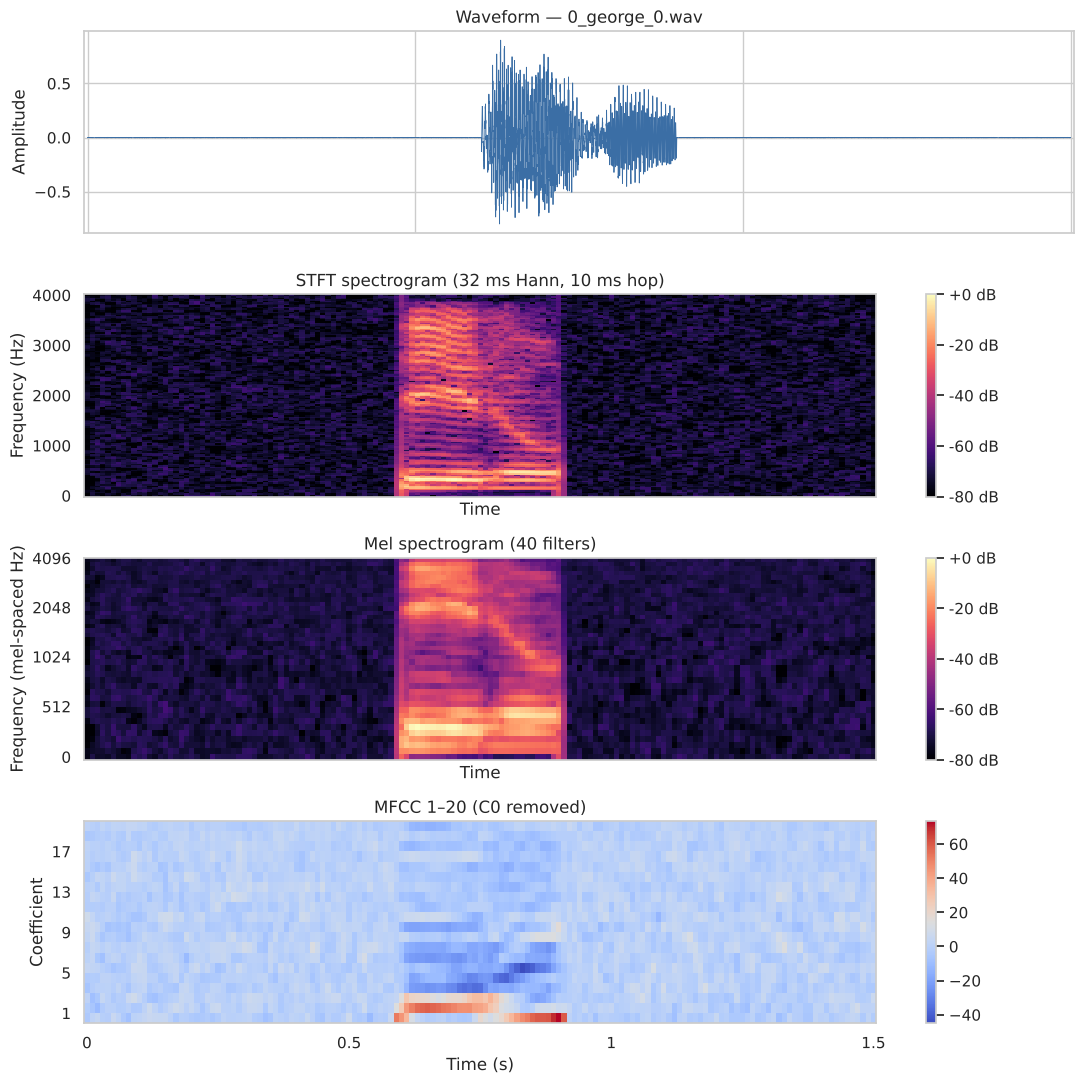

,Parameter,Value
0,Sampling rate,8000 Hz
1,Window,Hann
2,Frame length,256 samples (32 ms)
3,FFT size,256
4,Feature hop,80 samples (10 ms)
5,Enhancement hop,64 samples (75% overlap)
6,Mel filters,40
7,MFCCs used,"C1–C20 (+Δ, ΔΔ)"
8,Frequency resolution,31.25 Hz/bin
9,Frames per example,151


In [6]:
ex = idx["test"][0]
ex_name = os.path.basename(meta.path[ex])
x = CLEAN[ex]
t = np.arange(TOTAL_LEN) / SR

S_db   = librosa.amplitude_to_db(np.abs(librosa.stft(x, n_fft=N_FFT, hop_length=HOP_FEAT)), ref=np.max)
mel    = librosa.feature.melspectrogram(y=x, sr=SR, n_fft=N_FFT, hop_length=HOP_FEAT, n_mels=N_MELS)
mel_db = librosa.power_to_db(mel, ref=np.max)
mfcc   = scipy.fft.dct(librosa.power_to_db(mel), type=2, axis=0, norm="ortho")[1:N_MFCC + 1]

fig, ax = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
ax[0].plot(t, x, lw=0.6, color="#3b6ea5"); ax[0].set(title=f"Waveform — {ex_name}", ylabel="Amplitude")
img1 = librosa.display.specshow(S_db, sr=SR, hop_length=HOP_FEAT, x_axis="time", y_axis="linear", ax=ax[1], cmap="magma")
ax[1].set(title="STFT spectrogram (32 ms Hann, 10 ms hop)", ylabel="Frequency (Hz)")
fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")
img2 = librosa.display.specshow(mel_db, sr=SR, hop_length=HOP_FEAT, x_axis="time", y_axis="mel", ax=ax[2], cmap="magma")
ax[2].set(title=f"Mel spectrogram ({N_MELS} filters)", ylabel="Frequency (mel-spaced Hz)")
fig.colorbar(img2, ax=ax[2], format="%+2.0f dB")
img3 = librosa.display.specshow(mfcc, sr=SR, hop_length=HOP_FEAT, x_axis="time", ax=ax[3], cmap="coolwarm")
ax[3].set(title="MFCC 1–20 (C0 removed)", ylabel="Coefficient", xlabel="Time (s)")
ax[3].set_yticks(np.arange(0, N_MFCC, 4) + 0.5, np.arange(1, N_MFCC + 1, 4))
fig.colorbar(img3, ax=ax[3])
plt.tight_layout(); save(fig, "02_signal_analysis"); plt.show()

params = pd.DataFrame({
    "Parameter": ["Sampling rate", "Window", "Frame length", "FFT size", "Feature hop", "Enhancement hop",
                  "Mel filters", "MFCCs used", "Frequency resolution", "Frames per example"],
    "Value": [f"{SR} Hz", "Hann", f"{N_FFT} samples ({1000*N_FFT/SR:.0f} ms)", N_FFT,
              f"{HOP_FEAT} samples ({1000*HOP_FEAT/SR:.0f} ms)", f"{HOP_ENH} samples ({100*(1-HOP_ENH/N_FFT):.0f}% overlap)",
              N_MELS, f"C1–C{N_MFCC} (+Δ, ΔΔ)", f"{SR/N_FFT:.2f} Hz/bin", 1 + TOTAL_LEN // HOP_FEAT]})
params.to_csv(f"{OUT_DIR}/analysis_parameters.csv", index=False)
params

## Step 6 — Add noise in a controlled way

**Why:** the original code "enhanced" an already-clean recording, so there was nothing to measure. Here we *add* noise at a known signal-to-noise ratio:

$$\text{SNR}_{dB} = 10\log_{10}\frac{P_{speech}}{P_{noise}} \;\Rightarrow\; \text{noise is scaled by } \sqrt{\frac{P_{speech}}{P_{noise}\,10^{\text{SNR}/10}}}$$

Two noise types:
- **White noise**: flat spectrum, stationary. This is the easy case for spectral subtraction, because the noise estimate stays valid for the whole clip.
- **Babble noise**: 6 overlapping talkers built from **training-set** speech only (so no test speech leaks in). It is speech-shaped and fluctuating, much harder, and closer to a real crowded room.

Each test condition uses its own fixed random seed, so results are reproducible, and the *same* noisy signal is used for the noisy and enhanced comparisons.

In [7]:
def make_babble(n_talkers=6, seconds=600, rng=None):
    length = int(seconds * SR)
    streams = []
    for _ in range(n_talkers):
        parts, total = [], 0
        while total < length:
            k = rng.choice(idx["train"])
            parts.append(SPEECH_ONLY[k]); total += len(SPEECH_ONLY[k])
        streams.append(np.concatenate(parts)[:length])
    b = np.sum(streams, axis=0)
    return (b / np.sqrt(np.mean(b ** 2))).astype(np.float32)

BABBLE = make_babble(rng=np.random.default_rng(SEED + 1))

def get_noise(kind, n, rng):
    if kind == "white":
        return rng.standard_normal((n, TOTAL_LEN)).astype(np.float32)
    starts = rng.integers(0, len(BABBLE) - TOTAL_LEN, n)
    return np.stack([BABBLE[s:s + TOTAL_LEN] for s in starts])

def add_noise(clean, p_speech, kind, snr_db, rng):
    noise = get_noise(kind, len(clean), rng)
    snr = np.broadcast_to(np.asarray(snr_db, np.float32), (len(clean),))
    scale = np.sqrt(p_speech / (np.mean(noise ** 2, axis=1) * 10 ** (snr / 10)))
    return (clean + scale[:, None] * noise).astype(np.float32)

def cond_rng(*keys):
    # deterministic, independent random stream per condition
    return np.random.default_rng([SEED] + [zlib.crc32(str(k).encode()) for k in keys])

# sanity check: the SNR we asked for is the SNR we got
chk = idx["test"][:50]
for kind in NOISE_TYPES:
    noisy = add_noise(CLEAN[chk], P_SPEECH[chk], kind, 5, cond_rng("check", kind))
    measured = 10 * np.log10(P_SPEECH[chk] / np.mean((noisy - CLEAN[chk]) ** 2, axis=1))
    print(f"{kind:6s}: requested 5 dB -> measured {measured.mean():.2f} ± {measured.std():.2f} dB")

white : requested 5 dB -> measured 5.00 ± 0.00 dB
babble: requested 5 dB -> measured 5.00 ± 0.00 dB


## Step 7 — Spectral subtraction (vectorised)

**Idea (Boll 1979, with Berouti et al. 1979 improvements):** noise adds energy at every frequency. If we can estimate the noise power spectrum $\hat{N}(\omega)$, we subtract it from the noisy power spectrum in every frame:

$$|\hat{X}(m,\omega)|^2 = \max\!\Big(|Y(m,\omega)|^2 - \alpha\,|\hat{N}(\omega)|^2,\;\; \beta\,|Y(m,\omega)|^2\Big)$$

- **α (over-subtraction)** removes a bit more than the average noise, to suppress residual noise peaks.
- **β (spectral floor)** prevents bins hitting zero, which reduces the "musical noise" (random chirps) that plain subtraction creates.
- The **noisy phase** is reused, since the ear is not very sensitive to phase, and the signal is rebuilt with the inverse STFT using the same length as the input.

**Noise estimate:** instead of assuming "the first 0.5 s is silence", we take the **15 % lowest-energy frames** of each clip and average their power spectrum. This finds the pauses wherever they are.

**Efficiency:** `librosa.stft` / `istft` accept a whole batch `(n_clips, n_samples)`, and the noise estimate uses `argsort` + `take_along_axis`. There is no per-clip Python loop.

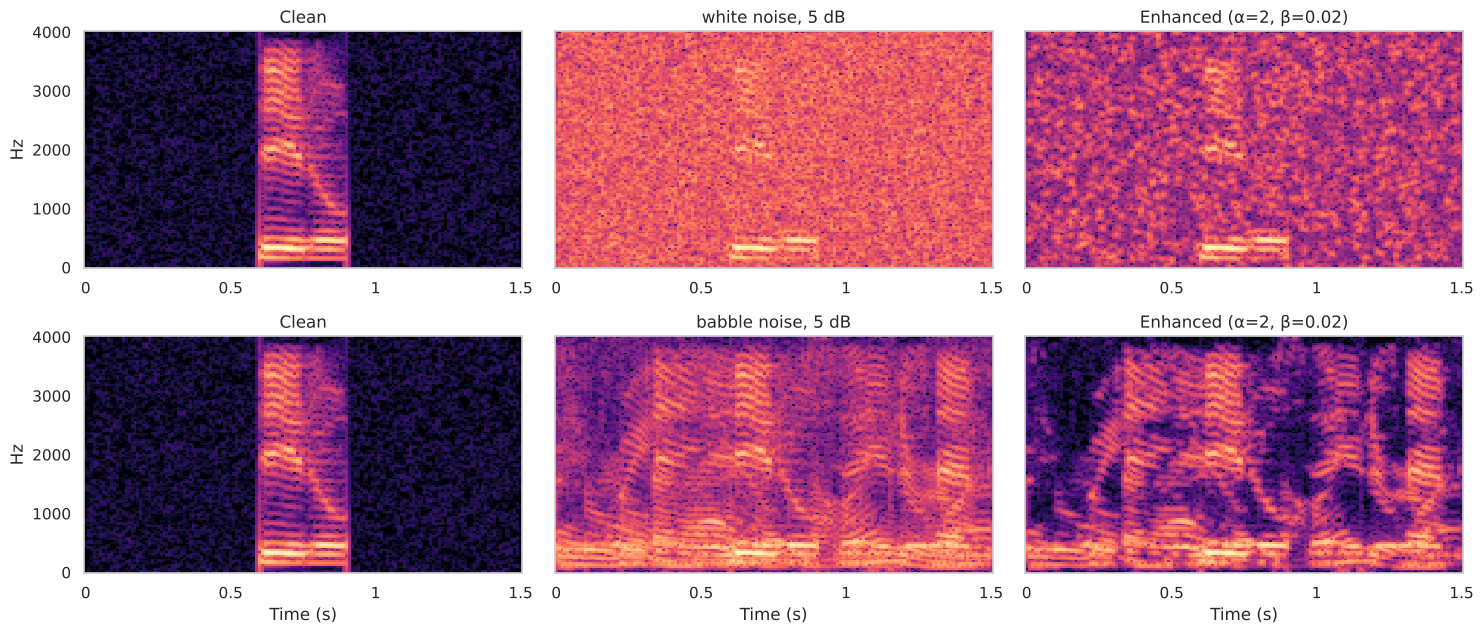

In [8]:
def spectral_subtract(y, alpha=2.0, beta=0.02, noise_frac=NOISE_FRAC):
    # y: (batch, samples) -> enhanced (batch, samples)
    Y = librosa.stft(y, n_fft=N_FFT, hop_length=HOP_ENH, window="hann")      # (B, F, T)
    P = np.abs(Y) ** 2
    phase = Y / (np.abs(Y) + 1e-12)
    T = P.shape[-1]
    k = max(5, int(noise_frac * T))
    quiet = np.argsort(P.sum(axis=1), axis=1)[:, :k]                         # lowest-energy frames
    N_hat = np.take_along_axis(P, quiet[:, None, :], axis=2).mean(axis=2, keepdims=True)
    P_clean = np.maximum(P - alpha * N_hat, beta * P)
    X = np.sqrt(P_clean) * phase
    return librosa.istft(X, hop_length=HOP_ENH, window="hann", length=y.shape[-1]).astype(np.float32)

def enhance(y, alpha, beta):
    return batched(spectral_subtract, y, bs=256, alpha=alpha, beta=beta)

# quick visual check with default parameters (tuned properly in Step 10)
demo = {}
for kind in NOISE_TYPES:
    noisy = add_noise(CLEAN[[ex]], P_SPEECH[[ex]], kind, 5, cond_rng("demo", kind))
    demo[kind] = (noisy[0], enhance(noisy, 2.0, 0.02)[0])

fig, ax = plt.subplots(2, 3, figsize=(15, 6.5), sharey=True)
for r, kind in enumerate(NOISE_TYPES):
    for c, (lab, sig) in enumerate([("Clean", x), (f"{kind} noise, 5 dB", demo[kind][0]),
                                     ("Enhanced (α=2, β=0.02)", demo[kind][1])]):
        D = librosa.amplitude_to_db(np.abs(librosa.stft(sig, n_fft=N_FFT, hop_length=HOP_FEAT)), ref=np.max(np.abs(librosa.stft(x, n_fft=N_FFT, hop_length=HOP_FEAT))))
        librosa.display.specshow(D, sr=SR, hop_length=HOP_FEAT, x_axis="time", y_axis="linear",
                                 ax=ax[r, c], cmap="magma", vmin=-80, vmax=0)
        ax[r, c].set(title=lab, xlabel="Time (s)" if r else "", ylabel="Hz" if c == 0 else "")
plt.tight_layout(); save(fig, "03_spectral_subtraction_demo"); plt.show()

## Step 8 — Feature extraction: MFCC + Δ + ΔΔ (batched)

For every 10 ms frame we compute 20 MFCCs, plus their **first (Δ)** and **second (ΔΔ) time-derivatives**, which capture how the spectrum is *changing*. These are stacked as 3 "colour channels", giving each example an image-like array of shape **20 coefficients × 151 frames × 3**.

The pipeline is power STFT → mel filterbank (one `einsum` for the whole batch) → dB → DCT-II → keep C1–C20 → Δ, ΔΔ.

**Standardisation:** each coefficient/channel is scaled to zero mean and unit variance using statistics from the **training set only**, which avoids test-set leakage. Unscaled MFCCs (C1 ≈ ±100, C20 ≈ ±5) make training slow and unstable.

**Test features for all 18 conditions are computed once and reused** by both models.

In [9]:
MEL_FB = librosa.filters.mel(sr=SR, n_fft=N_FFT, n_mels=N_MELS, fmin=20, fmax=SR / 2).astype(np.float32)

def _mfcc_batch(y):
    S = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP_FEAT, window="hann")) ** 2   # (B, F, T)
    M = np.einsum("mf,bft->bmt", MEL_FB, S)
    logM = 10 * np.log10(np.maximum(M, 1e-10))
    C = scipy.fft.dct(logM, type=2, axis=1, norm="ortho")[:, 1:N_MFCC + 1]
    d1 = librosa.feature.delta(C, width=9, order=1, axis=-1)
    d2 = librosa.feature.delta(C, width=9, order=2, axis=-1)
    return np.stack([C, d1, d2], axis=-1).astype(np.float32)                           # (B, 20, T, 3)

def features(y):
    return batched(_mfcc_batch, y, bs=512)

class Standardizer:
    def fit(self, X):
        self.mu = X.mean(axis=(0, 2), keepdims=True)
        self.sd = X.std(axis=(0, 2), keepdims=True) + 1e-6
        return self
    def __call__(self, X):
        return ((X - self.mu) / self.sd).astype(np.float32)

t0 = time.time()
F_clean = features(CLEAN)
print(f"Features for {len(CLEAN)} clips: {F_clean.shape} in {time.time()-t0:.1f} s")

Features for 3000 clips: (3000, 20, 151, 3) in 2.1 s


## Step 9 — Model A: CNN trained on clean speech

**Architecture (small, fast, regularised):**
- 4 convolution blocks (32→32→64→128 filters, 3×3) with **Batch Normalisation**, which stabilises and speeds up training.
- **Max-pooling** to shrink the feature map, then **Global Average Pooling**. GAP replaces `Flatten + Dense(128)` from the original code, using far fewer parameters and overfitting less.
- **Dropout** before the softmax layer with 10 outputs (digits 0–9).

**Training tricks:**
- **SpecAugment**: randomly blanks a band of up to 3 coefficients and up to 15 frames in each training example, so the network can't rely on any single region.
- **Early stopping** on validation loss, restoring the best weights, and **ReduceLROnPlateau**, which halves the learning rate when progress stalls.
- **`tf.data` pipeline** with `cache → shuffle → batch → augment → prefetch`, so the GPU or CPU never waits for data.

model_A_clean: 56 epochs in 536 s | best val acc 1.0000 | params 104,554


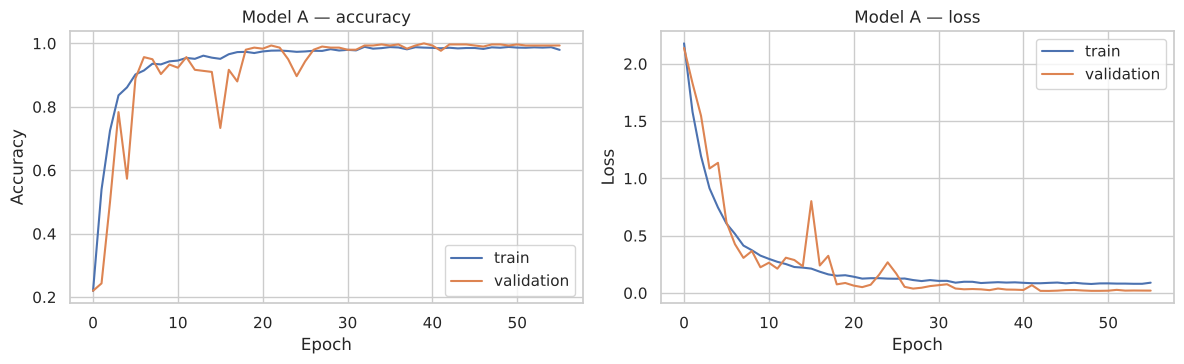

In [10]:
def spec_augment(x, y):
    B = tf.shape(x)[0]; Fd = x.shape[1]; Td = x.shape[2]
    f  = tf.random.uniform([B, 1, 1, 1], 0, 4, tf.int32)
    f0 = tf.random.uniform([B, 1, 1, 1], 0, Fd - 3, tf.int32)
    t  = tf.random.uniform([B, 1, 1, 1], 0, 16, tf.int32)
    t0 = tf.random.uniform([B, 1, 1, 1], 0, Td - 15, tf.int32)
    fr = tf.range(Fd)[None, :, None, None]; tr = tf.range(Td)[None, None, :, None]
    keep = ~(((fr >= f0) & (fr < f0 + f)) | ((tr >= t0) & (tr < t0 + t)))
    return x * tf.cast(keep, x.dtype), y

def make_ds(X, y, train):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if train:
        ds = ds.cache().shuffle(len(X), seed=SEED, reshuffle_each_iteration=True).batch(BATCH)
        if SPECAUGMENT:
            ds = ds.map(spec_augment, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.batch(256)
    return ds.prefetch(tf.data.AUTOTUNE)

def build_model(input_shape, n_classes=10):
    def block(z, f, pool):
        z = layers.Conv2D(f, 3, padding="same", use_bias=False)(z)
        z = layers.BatchNormalization()(z)
        z = layers.ReLU()(z)
        return layers.MaxPooling2D(2)(z) if pool else z
    inp = layers.Input(input_shape)
    z = block(inp, 32, False)
    z = block(z, 32, True)
    z = block(z, 64, True)
    z = layers.Dropout(0.2)(z)
    z = block(z, 128, False)
    z = layers.GlobalAveragePooling2D()(z)
    z = layers.Dropout(0.3)(z)
    out = layers.Dense(n_classes, activation="softmax", dtype="float32")(z)
    m = models.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(LR),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def train(Xtr, ytr, Xva, yva, name):
    tf.keras.utils.set_random_seed(SEED)
    m = build_model(Xtr.shape[1:])
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
           callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)]
    t0 = time.time()
    h = m.fit(make_ds(Xtr, ytr, True), validation_data=make_ds(Xva, yva, False),
              epochs=EPOCHS, callbacks=cbs, verbose=0)
    print(f"{name}: {len(h.history['loss'])} epochs in {time.time()-t0:.0f} s | "
          f"best val acc {max(h.history['val_accuracy']):.4f} | params {m.count_params():,}")
    m.save(f"{OUT_DIR}/{name}.keras")
    return m, h

def predict(m, X):
    return m.predict(X, batch_size=512, verbose=0).argmax(axis=1)

normA = Standardizer().fit(F_clean[idx["train"]])
modelA, histA = train(normA(F_clean[idx["train"]]), y_all[idx["train"]],
                      normA(F_clean[idx["val"]]), y_all[idx["val"]], "model_A_clean")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, a in zip(["accuracy", "loss"], ax):
    a.plot(histA.history[k], label="train"); a.plot(histA.history["val_" + k], label="validation")
    a.set(title=f"Model A — {k}", xlabel="Epoch", ylabel=k.capitalize()); a.legend()
plt.tight_layout(); save(fig, "04_training_curves_modelA"); plt.show()

## Step 10 — Tune α and β on the **validation** set

**What we're doing:** spectral subtraction has two knobs. Instead of guessing (the original code used α = 1.5), we try every combination in the grid and pick the pair that gives Model A the **highest average validation accuracy** across white and babble noise at 10, 5 and 0 dB.

**Why validation and not test:** if we tuned on the test set, the final test numbers would be optimistically biased. The test set stays untouched until Step 11.

Grid search (18 settings) in 105 s
Mean validation accuracy without enhancement: 0.5283
Best: alpha = 4.0, beta = 0.3 -> mean validation accuracy 0.5433


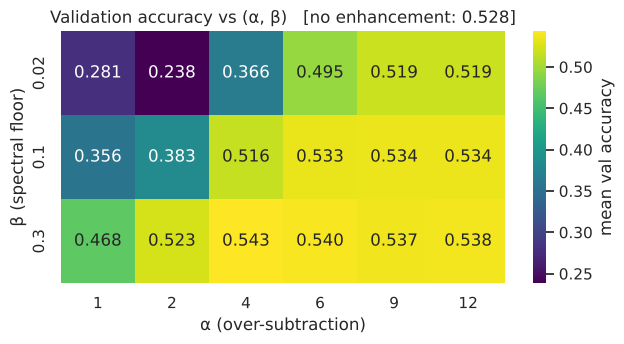

In [11]:
VAL_NOISY = {(k, s): add_noise(CLEAN[idx["val"]], P_SPEECH[idx["val"]], k, s, cond_rng("val", k, s))
             for k in NOISE_TYPES for s in TUNE_SNRS}
yv = y_all[idx["val"]]

rows = []
t0 = time.time()
for a in ALPHA_GRID:
    for b in BETA_GRID:
        accs = {}
        for (k, s), Yn in VAL_NOISY.items():
            accs[(k, s)] = accuracy_score(yv, predict(modelA, normA(features(enhance(Yn, a, b)))))
        rows.append({"alpha": a, "beta": b, "mean_val_acc": np.mean(list(accs.values())),
                     **{f"{k}_{s}dB": v for (k, s), v in accs.items()}})
tune = pd.DataFrame(rows)
noisy_val_acc = np.mean([accuracy_score(yv, predict(modelA, normA(features(Yn)))) for Yn in VAL_NOISY.values()])
best = tune.loc[tune.mean_val_acc.idxmax()]
ALPHA, BETA = float(best.alpha), float(best.beta)
tune.to_csv(f"{OUT_DIR}/alpha_beta_tuning.csv", index=False)
print(f"Grid search ({len(tune)} settings) in {time.time()-t0:.0f} s")
print(f"Mean validation accuracy without enhancement: {noisy_val_acc:.4f}")
print(f"Best: alpha = {ALPHA}, beta = {BETA} -> mean validation accuracy {best.mean_val_acc:.4f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.heatmap(tune.pivot(index="beta", columns="alpha", values="mean_val_acc"), annot=True, fmt=".3f",
            cmap="viridis", ax=ax, cbar_kws={"label": "mean val accuracy"})
ax.set(title=f"Validation accuracy vs (α, β)   [no enhancement: {noisy_val_acc:.3f}]",
       xlabel="α (over-subtraction)", ylabel="β (spectral floor)")
plt.tight_layout(); save(fig, "05_alpha_beta_tuning"); plt.show()

## Step 11 — Build the test conditions and measure enhancement quality

**Test conditions (18):** clean, clean→enhanced, and {white, babble} × {20, 10, 5, 0 dB} × {noisy, enhanced}.

*Clean → enhanced* answers a question the original report raised implicitly: **what does spectral subtraction do to speech that has no noise?**

**Objective metrics (all computed against the clean reference):**
| Metric | Meaning | Range |
|---|---|---|
| **SNR** | overall error energy vs speech energy | dB, higher = better |
| **SegSNR** | SNR averaged over 16 ms speech frames (closer to perception) | dB, clipped to [−10, 35] |
| **PESQ** (narrow-band) | predicted listener quality score | ≈1–4.5 |
| **STOI** | predicted intelligibility (computed on groups of 10 concatenated clips, because STOI needs ≥ 0.4 s of speech and one digit is shorter) | 0–1 |

**Efficiency:** SNR/SegSNR are fully vectorised, STOI runs in parallel with `joblib`, and PESQ uses `pesq_batch` with multiprocessing.

18 test conditions x 300 clips ready


Metrics computed in 43 s  (PESQ: True, STOI: True)


PESQ               SNR             STOI            SegSNR  \
input         enhanced  noisy   enhanced   noisy enhanced  noisy   enhanced   
noise  snr_db                                                                 
babble 0.0       1.537  1.575  -3.579000  -5.652    0.614  0.620  -1.783000   
       5.0       1.787  1.813   1.316000  -0.652    0.754  0.755   1.867000   
       10.0      2.187  2.180   6.272000   4.348    0.858  0.857   5.925000   
       20.0      3.162  3.080  16.169001  14.348    0.973  0.973  14.816000   
clean  inf       4.545    NaN  52.313000     NaN    1.000    NaN  34.609001   
white  0.0       1.698  1.671  -0.777000  -5.652    0.670  0.655  -0.784000   
       5.0       1.848  1.798   4.109000  -0.652    0.765  0.751   2.923000   
       10.0      2.129  1.993   8.946000   4.348    0.847  0.835   6.938000   
       20.0      3.097  2.780  18.475000  14.348    0.958  0.953  15.477000   

                       
input           noisy  
noise  snr_db          
babble 0.0     -2.891  
       5.0      0.778  
       10.0     4.953  
       20.0    14.113  
clean  inf        NaN  
white  0.0     -3.602  
       5.0     -0.115  
       10.0     3.918  
       20.0    13.140

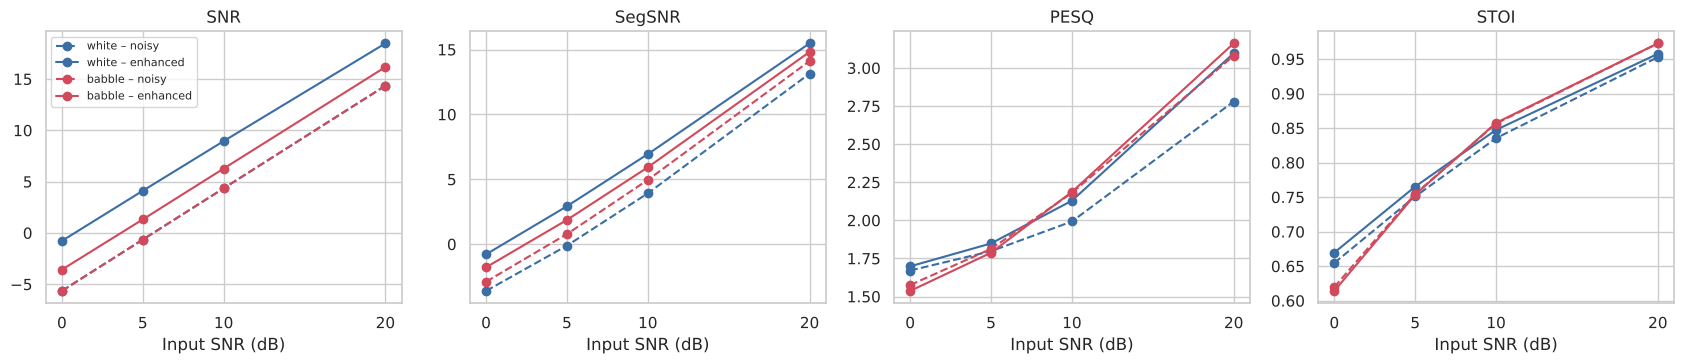

In [12]:
Xte_clean = CLEAN[idx["test"]]; yte = y_all[idx["test"]]

TEST = {("clean", np.inf, "noisy"): Xte_clean,
        ("clean", np.inf, "enhanced"): enhance(Xte_clean, ALPHA, BETA)}
for k in NOISE_TYPES:
    for s in SNRS:
        Yn = add_noise(Xte_clean, P_SPEECH[idx["test"]], k, s, cond_rng("test", k, s))
        TEST[(k, s, "noisy")] = Yn
        TEST[(k, s, "enhanced")] = enhance(Yn, ALPHA, BETA)
F_TEST = {key: features(w) for key, w in TEST.items()}
print(f"{len(TEST)} test conditions x {len(yte)} clips ready")

# ---------- metrics ----------
try:
    from pesq import pesq_batch, PesqError
    HAVE_PESQ = True
except Exception:
    HAVE_PESQ = False
try:
    from pystoi import stoi
    HAVE_STOI = True
except Exception:
    HAVE_STOI = False

def snr_db(ref, est):
    return 10 * np.log10(np.sum(ref ** 2, 1) / (np.sum((ref - est) ** 2, 1) + 1e-12))

def segsnr_db(ref, est, frame=128, hop=64):
    R = librosa.util.frame(ref, frame_length=frame, hop_length=hop, axis=-1)
    E = librosa.util.frame(est, frame_length=frame, hop_length=hop, axis=-1)
    num = np.sum(R ** 2, axis=-2); den = np.sum((R - E) ** 2, axis=-2) + 1e-12
    seg = np.clip(10 * np.log10(num / den + 1e-12), -10, 35)
    active = num > num.max(axis=1, keepdims=True) * 1e-4          # speech frames only (-40 dB)
    return np.nanmean(np.where(active, seg, np.nan), axis=1)

def pesq_scores(ref, est):
    if not HAVE_PESQ:
        return np.full(len(ref), np.nan)
    out = pesq_batch(SR, ref.astype(np.float64), est.astype(np.float64), "nb",
                     n_processor=N_JOBS, on_error=PesqError.RETURN_VALUES)
    out = np.array(out, dtype=float)
    out[out < 0] = np.nan                                         # error codes -> NaN
    return out

def stoi_scores(ref, est, group=10):
    # STOI needs >= ~0.4 s of active speech; one digit is shorter, so pystoi would return 1e-5.
    # We therefore score groups of 10 consecutive clips concatenated end-to-end.
    if not HAVE_STOI:
        return np.full(1, np.nan)
    n = len(ref) // group * group
    R = ref[:n].reshape(-1, group * ref.shape[1]); E = est[:n].reshape(-1, group * est.shape[1])
    return np.array(Parallel(n_jobs=N_JOBS)(delayed(stoi)(r, e, SR, False) for r, e in zip(R, E)))

t0 = time.time()
rows = []
for (k, s, proc), W in TEST.items():
    if k == "clean" and proc == "noisy":
        continue                                                  # clean vs itself is trivial
    rows.append({"noise": k, "snr_db": s, "input": proc,
                 "SNR": snr_db(Xte_clean, W).mean(), "SegSNR": segsnr_db(Xte_clean, W).mean(),
                 "PESQ": np.nanmean(pesq_scores(Xte_clean, W)), "STOI": stoi_scores(Xte_clean, W).mean()})
enh_metrics = pd.DataFrame(rows)
enh_metrics.to_csv(f"{OUT_DIR}/enhancement_metrics.csv", index=False)
print(f"Metrics computed in {time.time()-t0:.0f} s  (PESQ: {HAVE_PESQ}, STOI: {HAVE_STOI})")

table = enh_metrics.pivot_table(index=["noise", "snr_db"], columns="input",
                                values=["SNR", "SegSNR", "PESQ", "STOI"]).round(3)
display(table)

fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, m in zip(ax, ["SNR", "SegSNR", "PESQ", "STOI"]):
    for k, c in zip(NOISE_TYPES, ["#3b6ea5", "#d1495b"]):
        for proc, ls in [("noisy", "--"), ("enhanced", "-")]:
            d = enh_metrics.query("noise == @k and input == @proc").sort_values("snr_db")
            a.plot(d.snr_db, d[m], ls, marker="o", color=c, label=f"{k} – {proc}")
    a.set(title=m, xlabel="Input SNR (dB)"); a.set_xticks(SNRS)
ax[0].legend(fontsize=8)
plt.tight_layout(); save(fig, "06_enhancement_metrics"); plt.show()

### Listen to an example

Below are the clean, noisy (5 dB) and enhanced versions of the same test clip. Listening is the quickest way to hear what the metrics mean, including any **musical noise** spectral subtraction leaves behind. The WAV files are also saved to the outputs folder.

In [13]:
j = 0
for key in [("clean", np.inf, "noisy"), ("white", 5, "noisy"), ("white", 5, "enhanced"),
            ("babble", 5, "noisy"), ("babble", 5, "enhanced")]:
    w = TEST[key][j]
    name = "clean" if key[0] == "clean" else f"{key[0]}_{key[1]}dB_{key[2]}"
    sf.write(f"{OUT_DIR}/example_{name}.wav", w / (np.abs(w).max() + 1e-9) * 0.9, SR)
    print(name); display(Audio(w, rate=SR))

clean


white_5dB_noisy


white_5dB_enhanced


babble_5dB_noisy


babble_5dB_enhanced


## Step 12 — Robustness experiment (the headline result)

**What we're doing:** Model A was trained on **clean** speech only. We now test it on every condition and ask:
1. How fast does accuracy fall as noise increases? This is the **train/test mismatch** problem.
2. Does spectral subtraction *before* feature extraction recover some of that accuracy?

We also show the confusion matrix on clean speech and on the hardest condition, to see *which* digits get confused.

Model A — clean test accuracy: 1.0000
Model A — clean speech AFTER spectral subtraction: 1.0000



              precision    recall  f1-score   support

           0      1.000     1.000     1.000        30
           1      1.000     1.000     1.000        30
           2      1.000     1.000     1.000        30
           3      1.000     1.000     1.000        30
           4      1.000     1.000     1.000        30
           5      1.000     1.000     1.000        30
           6      1.000     1.000     1.000        30
           7      1.000     1.000     1.000        30
           8      1.000     1.000     1.000        30
           9      1.000     1.000     1.000        30

    accuracy                          1.000       300
   macro avg      1.000     1.000     1.000       300
weighted avg      1.000     1.000     1.000       300



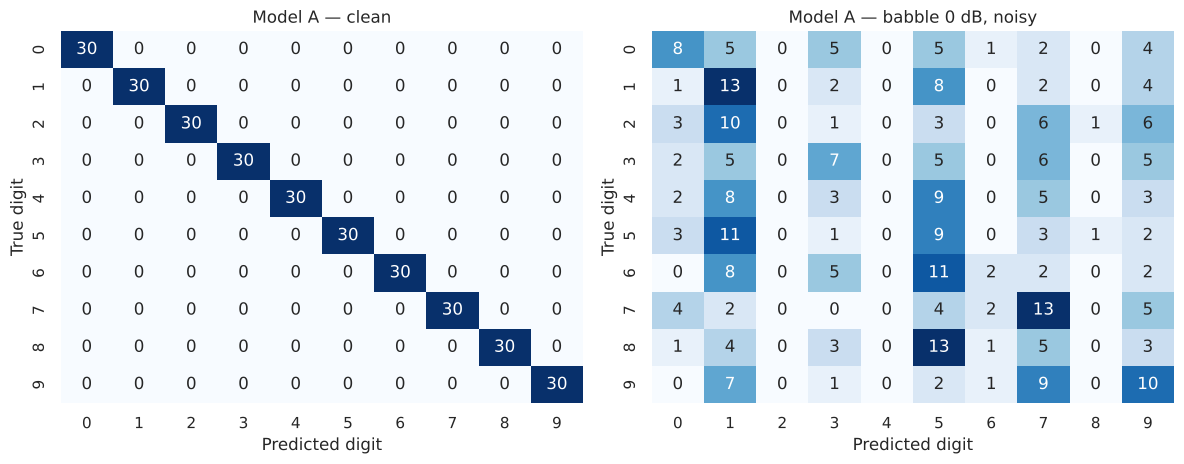

In [14]:
def evaluate_grid(model, norm, name):
    rows = []
    for (k, s, proc), F in F_TEST.items():
        rows.append({"model": name, "noise": k, "snr_db": s, "input": proc,
                     "accuracy": accuracy_score(yte, predict(model, norm(F)))})
    return pd.DataFrame(rows)

resA = evaluate_grid(modelA, normA, "A (clean-trained)")
accA_clean = resA.query("noise == 'clean' and input == 'noisy'").accuracy.item()
print(f"Model A — clean test accuracy: {accA_clean:.4f}")
accA_clean_enh = resA.query("noise == 'clean' and input == 'enhanced'").accuracy.item()
print(f"Model A — clean speech AFTER spectral subtraction: {accA_clean_enh:.4f}\n")
print(classification_report(yte, predict(modelA, normA(F_TEST[('clean', np.inf, 'noisy')])), digits=3))

worst = ("babble", 0, "noisy")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for a, key, title in [(ax[0], ("clean", np.inf, "noisy"), "clean"), (ax[1], worst, "babble 0 dB, noisy")]:
    cm = confusion_matrix(yte, predict(modelA, normA(F_TEST[key])), labels=range(10))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a)
    a.set(title=f"Model A — {title}", xlabel="Predicted digit", ylabel="True digit")
plt.tight_layout(); save(fig, "07_confusion_matrices_modelA"); plt.show()

## Step 13 — Model B: multi-condition training

**What we're doing:** the other standard way to get noise robustness is to **show the model noisy speech during training**. Model B uses the same architecture, but its training set is every clean training clip **plus** a noisy copy of each, with a random noise type (white/babble) and a random SNR between 0 and 20 dB. Its validation set is built the same way from validation clips.

This lets the report compare two strategies:
- **Front-end enhancement** (clean the audio, keep the clean-trained model)
- **Back-end robustness** (train the model on noisy data)
- and their **combination** (Model B + enhanced input)

model_B_multicondition: 80 epochs in 1533 s | best val acc 0.9133 | params 104,554


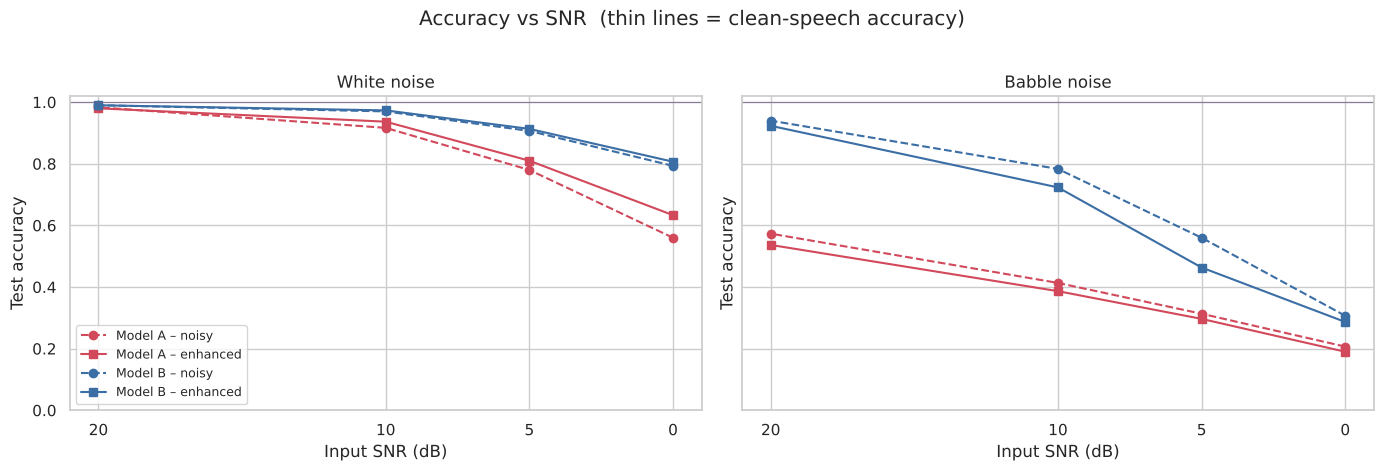

model         A (clean-trained)        B (multi-condition)       
input                  enhanced  noisy            enhanced  noisy
noise  snr_db                                                    
babble 0.0                0.190  0.207               0.287  0.307
       5.0                0.297  0.313               0.463  0.560
       10.0               0.387  0.413               0.723  0.783
       20.0               0.537  0.573               0.923  0.940
clean  inf                1.000  1.000               1.000  1.000
white  0.0                0.633  0.560               0.807  0.793
       5.0                0.810  0.780               0.913  0.907
       10.0               0.937  0.917               0.973  0.970
       20.0               0.980  0.983               0.990  0.990

In [15]:
def multicondition(ix, tag):
    rng = cond_rng("multi", tag)
    kinds = rng.choice(NOISE_TYPES, len(ix))
    snrs = rng.uniform(0, 20, len(ix)).astype(np.float32)
    noisy = np.empty((len(ix), TOTAL_LEN), np.float32)
    for k in NOISE_TYPES:
        m = kinds == k
        noisy[m] = add_noise(CLEAN[ix[m]], P_SPEECH[ix[m]], k, snrs[m], rng)
    X = np.concatenate([F_clean[ix], features(noisy)])
    y = np.concatenate([y_all[ix], y_all[ix]])
    return X, y

XtrB, ytrB = multicondition(idx["train"], "train")
XvaB, yvaB = multicondition(idx["val"], "val")
normB = Standardizer().fit(XtrB)
modelB, histB = train(normB(XtrB), ytrB, normB(XvaB), yvaB, "model_B_multicondition")
resB = evaluate_grid(modelB, normB, "B (multi-condition)")

results = pd.concat([resA, resB], ignore_index=True)
results.to_csv(f"{OUT_DIR}/accuracy_results.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
styles = {("A (clean-trained)", "noisy"): ("#d1495b", "--", "o"),
          ("A (clean-trained)", "enhanced"): ("#d1495b", "-", "s"),
          ("B (multi-condition)", "noisy"): ("#3b6ea5", "--", "o"),
          ("B (multi-condition)", "enhanced"): ("#3b6ea5", "-", "s")}
for a, k in zip(ax, NOISE_TYPES):
    for (mname, proc), (c, ls, mk) in styles.items():
        d = results.query("model == @mname and noise == @k and input == @proc").sort_values("snr_db")
        a.plot(d.snr_db, d.accuracy, ls=ls, marker=mk, color=c, label=f"Model {mname[0]} – {proc}")
    for mname, c in [("A (clean-trained)", "#d1495b"), ("B (multi-condition)", "#3b6ea5")]:
        a.axhline(results.query("model == @mname and noise == 'clean' and input == 'noisy'").accuracy.item(),
                  color=c, lw=0.8, alpha=0.5)
    a.set(title=f"{k.capitalize()} noise", xlabel="Input SNR (dB)", ylabel="Test accuracy", ylim=(0, 1.02))
    a.set_xticks(SNRS); a.invert_xaxis()
ax[0].legend(loc="lower left", fontsize=9)
fig.suptitle("Accuracy vs SNR  (thin lines = clean-speech accuracy)", y=1.02)
plt.tight_layout(); save(fig, "08_accuracy_vs_snr"); plt.show()

display(results.pivot_table(index=["noise", "snr_db"], columns=["model", "input"], values="accuracy").round(3))

## Step 14 — Automatic summary of findings

This cell turns the result tables into plain sentences you can check against the figures and adapt for the report's Results and Discussion sections. Everything it prints comes from the numbers above.

In [16]:
def acc(model, noise, snr, inp):
    m = (results.model.str[0] == model) & (results.noise == noise) & (results.snr_db == snr) & (results.input == inp)
    return results.loc[m, "accuracy"].item()

lines = []
lines.append(f"Dataset: FSDD, {len(meta)} recordings, {meta.speaker.nunique()} speakers, split = '{SPLIT_MODE}' "
             f"(train {len(idx['train'])}, val {len(idx['val'])}, test {len(idx['test'])}).")
lines.append(f"Model A clean test accuracy: {acc('A','clean',np.inf,'noisy'):.3f}; "
             f"Model B clean test accuracy: {acc('B','clean',np.inf,'noisy'):.3f}.")
d_clean = acc('A','clean',np.inf,'enhanced') - acc('A','clean',np.inf,'noisy')
lines.append(f"Spectral subtraction applied to CLEAN speech: Model A accuracy {acc('A','clean',np.inf,'enhanced'):.3f} "
             f"({d_clean:+.3f} vs unprocessed)" + (" -> enhancement costs accuracy when there is no noise." if d_clean < 0 else " -> harmless on clean speech."))
lines.append(f"Chosen enhancement parameters (validation): alpha = {ALPHA}, beta = {BETA}.")
for k in NOISE_TYPES:
    for s in SNRS:
        a_n, a_e = acc("A", k, s, "noisy"), acc("A", k, s, "enhanced")
        b_n, b_e = acc("B", k, s, "noisy"), acc("B", k, s, "enhanced")
        lines.append(f"{k:6s} {s:>2d} dB | A noisy {a_n:.3f} -> A enhanced {a_e:.3f} ({a_e-a_n:+.3f}) | "
                     f"B noisy {b_n:.3f} | B enhanced {b_e:.3f}")
for k in NOISE_TYPES:
    gainA = np.mean([acc("A", k, s, "enhanced") - acc("A", k, s, "noisy") for s in SNRS])
    gainB = np.mean([acc("B", k, s, "noisy") - acc("A", k, s, "noisy") for s in SNRS])
    lines.append(f"Average gain over Model A-noisy ({k}): enhancement {gainA:+.3f}, multi-condition training {gainB:+.3f}.")
for k in NOISE_TYPES:
    d = enh_metrics.query("noise == @k").set_index(["snr_db", "input"])
    lines.append(f"{k}: mean PESQ noisy {d.xs('noisy', level=1).PESQ.mean():.2f} -> enhanced "
                 f"{d.xs('enhanced', level=1).PESQ.mean():.2f}; mean STOI noisy {d.xs('noisy', level=1).STOI.mean():.3f} -> "
                 f"enhanced {d.xs('enhanced', level=1).STOI.mean():.3f}; mean SegSNR "
                 f"{d.xs('noisy', level=1).SegSNR.mean():.1f} -> {d.xs('enhanced', level=1).SegSNR.mean():.1f} dB.")

summary = "\n".join(lines)
print(summary)
with open(f"{OUT_DIR}/summary.txt", "w") as fh:
    fh.write(summary)
print("\nSaved files:")
for f in sorted(os.listdir(OUT_DIR)):
    print("  ", f)

Dataset: FSDD, 3000 recordings, 6 speakers, split = 'standard' (train 2400, val 300, test 300).
Model A clean test accuracy: 1.000; Model B clean test accuracy: 1.000.
Spectral subtraction applied to CLEAN speech: Model A accuracy 1.000 (+0.000 vs unprocessed) -> harmless on clean speech.
Chosen enhancement parameters (validation): alpha = 4.0, beta = 0.3.
white  20 dB | A noisy 0.983 -> A enhanced 0.980 (-0.003) | B noisy 0.990 | B enhanced 0.990
white  10 dB | A noisy 0.917 -> A enhanced 0.937 (+0.020) | B noisy 0.970 | B enhanced 0.973
white   5 dB | A noisy 0.780 -> A enhanced 0.810 (+0.030) | B noisy 0.907 | B enhanced 0.913
white   0 dB | A noisy 0.560 -> A enhanced 0.633 (+0.073) | B noisy 0.793 | B enhanced 0.807
babble 20 dB | A noisy 0.573 -> A enhanced 0.537 (-0.037) | B noisy 0.940 | B enhanced 0.923
babble 10 dB | A noisy 0.413 -> A enhanced 0.387 (-0.027) | B noisy 0.783 | B enhanced 0.723
babble  5 dB | A noisy 0.313 -> A enhanced 0.297 (-0.017) | B noisy 0.560 | B enhan

## How to interpret the results and use them in the report

**Pattern observed in the test run** (your numbers will differ slightly with hardware and library versions):
- Model A is essentially perfect on clean speech and **drops sharply as SNR falls**, far more with babble, because training and test conditions don't match. The babble here is made of *other digits spoken by the same speakers*, which makes it an especially confusing interferer.
- **Spectral subtraction raises SNR/SegSNR and PESQ for white noise but barely changes STOI.** It removes noise *and* some speech detail and leaves musical noise. For babble it helps very little, because one average noise spectrum can't describe a fluctuating crowd of talkers.
- For recognition, enhancement **helps the clean-trained model in white noise (most at 0 dB) but hurts it in babble**, where it subtracts parts of the target speech and distorts the features.
- **Multi-condition training (Model B) is clearly the stronger strategy** in both noise types, and feeding Model B enhanced audio gives almost nothing in white noise and makes it *worse* in babble, because the enhancement artefacts are a new kind of mismatch. That is a solid Discussion point: front-end enhancement and back-end training must be designed together.

**Figures → report sections**
| File | Use it in |
|---|---|
| `01_dataset_durations.png` | Methodology → Data |
| `02_signal_analysis.png` + `analysis_parameters.csv` | Fundamentals / Results: signal representations |
| `03_spectral_subtraction_demo.png` | Methodology → Enhancement (replaces the old Fig. 4) |
| `05_alpha_beta_tuning.png` | Methodology → Parameter tuning |
| `06_enhancement_metrics.png` + `enhancement_metrics.csv` | Results: enhancement quality |
| `04_training_curves_modelA.png`, `07_confusion_matrices_modelA.png` | Results: classifier |
| `08_accuracy_vs_snr.png` + `accuracy_results.csv` | **Main result** |
| `summary.txt` | Starting point for Discussion / Conclusion |

**Limitations to state honestly:** with the standard split the test speakers also appear in training (speaker-dependent); set `SPLIT_MODE = "speaker"` for a speaker-independent test. Noise is synthetic (additive white and babble), and FSDD has only 6 speakers.

**Natural extensions (Future Work):** Wiener filtering or MMSE-STSA enhancement, cepstral mean & variance normalisation (CMVN), real recorded noise (e.g. MUSAN/DEMAND), and training on enhanced speech.

**References to cite:**
S. F. Boll, "Suppression of acoustic noise in speech using spectral subtraction," *IEEE Trans. ASSP*, 27(2), 1979 ·
M. Berouti, R. Schwartz, J. Makhoul, "Enhancement of speech corrupted by acoustic noise," *ICASSP*, 1979 ·
S. Davis, P. Mermelstein, "Comparison of parametric representations for monosyllabic word recognition in continuously spoken sentences," *IEEE Trans. ASSP*, 28(4), 1980 ·
ITU-T Rec. P.862 (PESQ), 2001 ·
C. H. Taal et al., "An algorithm for intelligibility prediction of time–frequency weighted noisy speech," *IEEE Trans. ASLP*, 19(7), 2011 ·
D. S. Park et al., "SpecAugment," *Interspeech*, 2019 ·
Z. Jackson et al., Free Spoken Digit Dataset, Zenodo, doi:10.5281/zenodo.1342401.